In [ ]:
%pip install xgboost

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, ConfusionMatrixDisplay
)

In [ ]:
df = pd.read_csv('covertype.csv')

numeric_cols = [
    "Elevation", "Aspect", "Slope",
    "Horizontal_Distance_To_Hydrology", "Vertical_Distance_To_Hydrology",
    "Horizontal_Distance_To_Roadways",
    "Hillshade_9am", "Hillshade_Noon", "Hillshade_3pm",
    "Horizontal_Distance_To_Fire_Points",
]
wilderness_cols = [f"Wilderness_Area{i}" for i in range(1, 5)]
soil_cols = [f"Soil_Type{i}" for i in range(1, 41)]
target = "Cover_Type"

df.columns = numeric_cols + wilderness_cols + soil_cols + [target]
binary_cols = wilderness_cols + soil_cols

print(df.shape)
df.head()

(581012, 55)


,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Cover_Type
0,2596,51,3,258,0,510,221,232,148,6279,...,0,0,0,0,0,0,0,0,0,5
1,2590,56,2,212,-6,390,220,235,151,6225,...,0,0,0,0,0,0,0,0,0,5
2,2804,139,9,268,65,3180,234,238,135,6121,...,0,0,0,0,0,0,0,0,0,2
3,2785,155,18,242,118,3090,238,238,122,6211,...,0,0,0,0,0,0,0,0,0,2
4,2595,45,2,153,-1,391,220,234,150,6172,...,0,0,0,0,0,0,0,0,0,5


In [ ]:
df = df.replace(r"^\s*$", np.nan, regex=True)
df = df.replace(["?", "NA", "N/A", "null", "NULL", "-"], np.nan)
df[df.columns] = df[df.columns].apply(pd.to_numeric, errors="coerce")

print("Missing values per column (only columns with nulls):")
missing = df.isnull().sum()
print(missing[missing > 0] if (missing > 0).any() else "  none found")

Missing values per column (only columns with nulls):
  none found


In [ ]:
# never impute the target because it produces results
df = df.dropna(subset=[target])

# continuous columns: median
for c in numeric_cols:
    if df[c].isnull().any():
        df[c] = df[c].fillna(df[c].median())

# binary one-hot columns: mode (almost always 0).
for c in binary_cols:
    if df[c].isnull().any():
        df[c] = df[c].fillna(df[c].mode().iloc[0])

df[binary_cols + [target]] = df[binary_cols + [target]].astype("int8")

assert df.isnull().sum().sum() == 0, "Nulls remain"

In [ ]:
# Adding 10 engineered more columns
hdh = df["Horizontal_Distance_To_Hydrology"]
vdh = df["Vertical_Distance_To_Hydrology"]
road = df["Horizontal_Distance_To_Roadways"]
fire = df["Horizontal_Distance_To_Fire_Points"]
aspect_rad = np.deg2rad(df["Aspect"])

df["Hydro_Euclid_Dist"] = np.sqrt(hdh**2 + vdh**2)
df["Elev_Minus_VDH"] = df["Elevation"] - vdh
df["Elev_Minus_HDH_x0_2"] = df["Elevation"] - 0.2 * hdh
df["Hydro_Fire_Sum"] = hdh + fire
df["Hydro_Fire_AbsDiff"] = (hdh - fire).abs()
df["Hydro_Road_Sum"] = hdh + road
df["Fire_Road_Sum"] = fire + road
df["Hillshade_Mean"] = df[["Hillshade_9am", "Hillshade_Noon", "Hillshade_3pm"]].mean(axis=1)
df["Aspect_Sin"] = np.sin(aspect_rad)
df["Aspect_Cos"] = np.cos(aspect_rad)

In [ ]:
print(df.shape)

(581012, 65)


In [ ]:
print(df.isnull().sum().sum(), "missing values")
print(df['Cover_Type'].value_counts())

0 missing values
Cover_Type
2    283301
1    211840
3     35754
7     20510
6     17367
5      9493
4      2747
Name: count, dtype: int64


In [ ]:
X = df.drop(columns=['Cover_Type'])
y = df['Cover_Type']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(X_train.shape, X_test.shape)

(464809, 64) (116203, 64)


In [ ]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(
    max_depth=10,
    min_samples_leaf=5,
    random_state=42
)
dt.fit(X_train, y_train)

y_pred_dt = dt.predict(X_test)
y_proba_dt = dt.predict_proba(X_test)

In [ ]:
rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
y_proba_rf = rf.predict_proba(X_test)

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

# Scale features using training data only
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Initialize KNN
knn = KNeighborsClassifier(
    n_neighbors=5,
    weights='distance',
    n_jobs=-1
)

# Train KNN
knn.fit(X_train_scaled, y_train)

# Predictions
y_pred_knn = knn.predict(X_test_scaled)
y_proba_knn = knn.predict_proba(X_test_scaled)

print("KNN training and prediction completed.")

KNN training and prediction completed.


In [ ]:
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder

# Encode targets for XGBoost
label_encoder = LabelEncoder()

y_train_xgb = label_encoder.fit_transform(y_train)
y_test_xgb = label_encoder.transform(y_test)

# Initialize XGBoost
xgb = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    objective='multi:softprob',
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1,
    tree_method='hist'
)

# Train model
xgb.fit(X_train, y_train_xgb)

# Predict encoded classes
y_pred_xgb_encoded = xgb.predict(X_test)

# Convert predictions back to original class labels
y_pred_xgb = label_encoder.inverse_transform(
    y_pred_xgb_encoded
)

# Probability predictions
y_proba_xgb = xgb.predict_proba(X_test)

print("XGBoost training and prediction completed.")

XGBoost training and prediction completed.


In [ ]:
from sklearn.metrics import accuracy_score

# Decision Tree
train_acc_dt = accuracy_score(
    y_train, dt.predict(X_train)
) * 100

test_acc_dt = accuracy_score(
    y_test, y_pred_dt
) * 100


# Random Forest
train_acc_rf = accuracy_score(
    y_train, rf.predict(X_train)
) * 100

test_acc_rf = accuracy_score(
    y_test, y_pred_rf
) * 100


# XGBoost
# Convert encoded predictions back to original class labels
train_pred_xgb = label_encoder.inverse_transform(
    xgb.predict(X_train)
)

train_acc_xgb = accuracy_score(
    y_train, train_pred_xgb
) * 100

test_acc_xgb = accuracy_score(
    y_test, y_pred_xgb
) * 100


# KNN
# Use scaled features because KNN was trained on scaled data
train_acc_knn = accuracy_score(
    y_train, knn.predict(X_train_scaled)
) * 100

test_acc_knn = accuracy_score(
    y_test, y_pred_knn
) * 100


# Print results
print(f"Decision Tree — Train: {train_acc_dt:.2f}% | Test: {test_acc_dt:.2f}% | Gap: {train_acc_dt - test_acc_dt:.2f} pts")

print(f"Random Forest — Train: {train_acc_rf:.2f}% | Test: {test_acc_rf:.2f}% | Gap: {train_acc_rf - test_acc_rf:.2f} pts")

print(f"XGBoost — Train: {train_acc_xgb:.2f}% | Test: {test_acc_xgb:.2f}% | Gap: {train_acc_xgb - test_acc_xgb:.2f} pts")

print(f"KNN — Train: {train_acc_knn:.2f}% | Test: {test_acc_knn:.2f}% | Gap: {train_acc_knn - test_acc_knn:.2f} pts")

Decision Tree — Train: 79.89% | Test: 79.47% | Gap: 0.42 pts
Random Forest — Train: 83.24% | Test: 82.58% | Gap: 0.66 pts
XGBoost — Train: 82.73% | Test: 82.41% | Gap: 0.32 pts
KNN — Train: 100.00% | Test: 94.12% | Gap: 5.88 pts


===== Decision Tree =====
Accuracy : 79.47%
Precision: 79.59%
Recall   : 79.47%
F1 Score : 79.15%
AUC (OvR): 90.74%


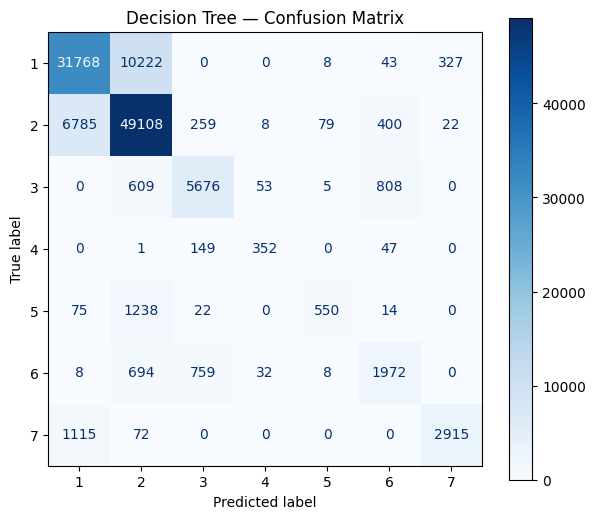

===== Random Forest =====
Accuracy : 82.58%
Precision: 82.97%
Recall   : 82.58%
F1 Score : 82.15%
AUC (OvR): 94.52%


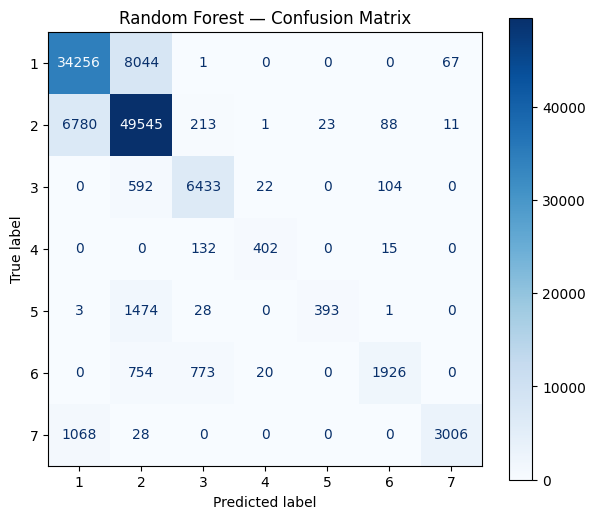

===== KNN =====
Accuracy : 94.12%
Precision: 94.12%
Recall   : 94.12%
F1 Score : 94.12%
AUC (OvR): 98.81%


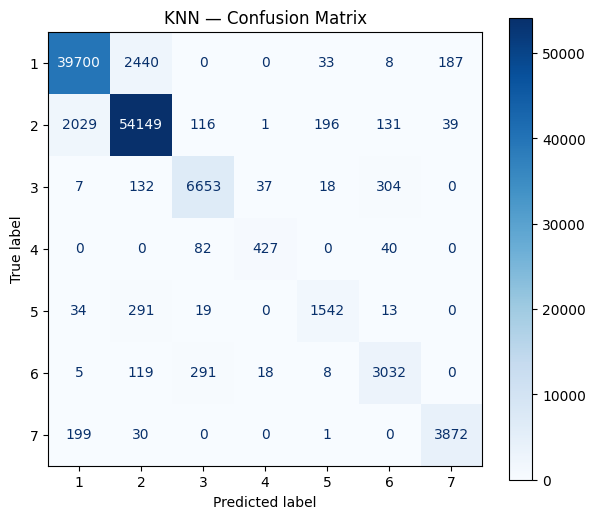

===== XGBoost =====
Accuracy : 82.41%
Precision: 82.47%
Recall   : 82.41%
F1 Score : 82.20%
AUC (OvR): 94.24%


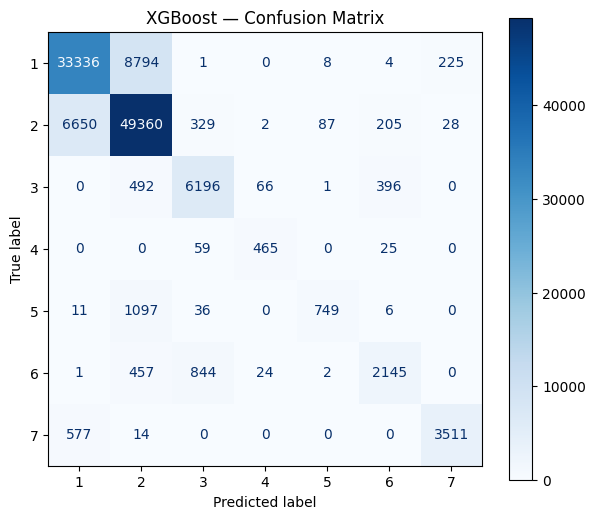

In [ ]:
def evaluate_model(name, y_true, y_pred, y_proba, classes):
    acc = accuracy_score(y_true, y_pred) * 100
    prec = precision_score(y_true, y_pred, average='weighted', zero_division=0) * 100
    rec = recall_score(y_true, y_pred, average='weighted', zero_division=0) * 100
    f1 = f1_score(y_true, y_pred, average='weighted', zero_division=0) * 100

    # Multiclass AUC needs one-vs-rest binarized labels
    auc = roc_auc_score(y_true, y_proba, average='weighted', multi_class='ovr') * 100

    print(f"===== {name} =====")
    print(f"Accuracy : {acc:.2f}%")
    print(f"Precision: {prec:.2f}%")
    print(f"Recall   : {rec:.2f}%")
    print(f"F1 Score : {f1:.2f}%")
    print(f"AUC (OvR): {auc:.2f}%")

    cm = confusion_matrix(y_true, y_pred, labels=classes)
    fig, ax = plt.subplots(figsize=(7, 6))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes)
    disp.plot(ax=ax, cmap='Blues', values_format='d')
    plt.title(f"{name} — Confusion Matrix")
    plt.show()

    return {'Model': name, 'Accuracy %': acc, 'Precision %': prec,
            'Recall %': rec, 'F1 %': f1, 'AUC %': auc}

classes = sorted(y.unique())

# Decision Tree
results_dt = evaluate_model(
    "Decision Tree",
    y_test, y_pred_dt, y_proba_dt, classes
)

# Random Forest
results_rf = evaluate_model(
    "Random Forest",
    y_test, y_pred_rf, y_proba_rf, classes
)

# KNN
results_knn = evaluate_model(
    "KNN",
    y_test, y_pred_knn, y_proba_knn, classes
)

# XGBoost
results_xgb = evaluate_model(
    "XGBoost",
    y_test, y_pred_xgb, y_proba_xgb, classes
)

In [ ]:
comparison_df = pd.DataFrame([
    results_dt,
    results_rf,
    results_knn,
    results_xgb
]).set_index('Model')

comparison_df = comparison_df.round(2)

display(comparison_df)

,Accuracy %,Precision %,Recall %,F1 %,AUC %
Model,,,,,
Decision Tree,79.47,79.59,79.47,79.15,90.74
Random Forest,82.58,82.97,82.58,82.15,94.52
KNN,94.12,94.12,94.12,94.12,98.81
XGBoost,82.41,82.47,82.41,82.20,94.24


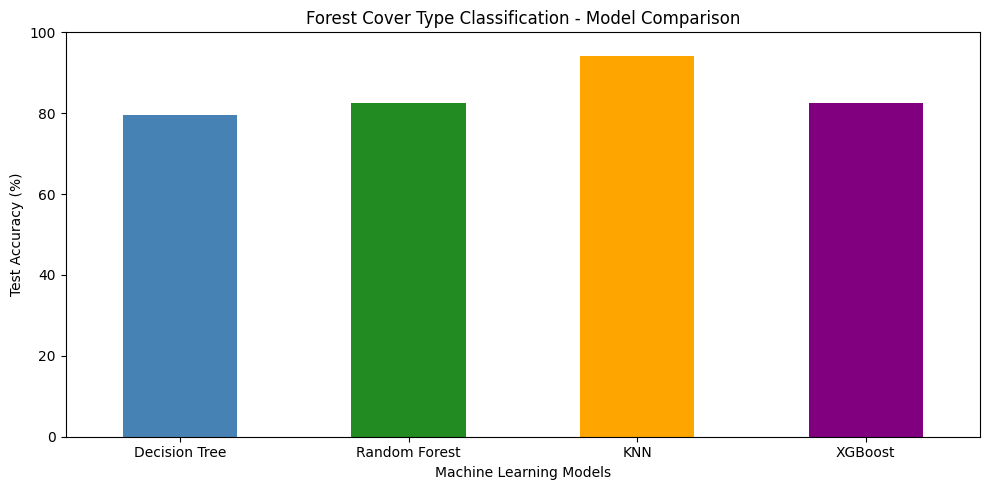

In [ ]:
plt.figure(figsize=(10, 5))

comparison_df['Accuracy %'].plot(
    kind='bar',
    color=['steelblue', 'forestgreen', 'orange', 'purple']
)

plt.title('Forest Cover Type Classification - Model Comparison')
plt.xlabel('Machine Learning Models')
plt.ylabel('Test Accuracy (%)')
plt.ylim(0, 100)
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [ ]:
ranked_models = comparison_df.sort_values(
    by='Accuracy %',
    ascending=False
)

print("Model ranking based on test accuracy:")
print(ranked_models[['Accuracy %']])

best_model = ranked_models.index[0]
best_accuracy = ranked_models.iloc[0]['Accuracy %']

print(f"\nBest model: {best_model}")
print(f"Test accuracy: {best_accuracy:.2f}%")

Model ranking based on test accuracy:
               Accuracy %
Model                    
KNN                 94.12
Random Forest       82.58
XGBoost             82.41
Decision Tree       79.47

Best model: KNN
Test accuracy: 94.12%


In [ ]:
import joblib

joblib.dump(rf, "rf_model.pkl")

['rf_model.pkl']

In [ ]:

import joblib

# Keep the original 54 input features in their training order
base_feature_columns = numeric_cols + wilderness_cols + soil_cols

# Store the fitted model and preprocessing information together
model_bundle = {
    "model": rf,
    "numeric_cols": numeric_cols,
    "binary_cols": binary_cols,
    "base_feature_columns": base_feature_columns,
    "feature_columns": list(X.columns),
    "numeric_medians": {
        col: float(df[col].median()) for col in numeric_cols
    },
    "binary_modes": {
        col: int(df[col].mode().iloc[0]) for col in binary_cols
    },
    "target": target,
    "model_version": "1.0"
}

joblib.dump(model_bundle, "rf_model_bundle.joblib")

print("Model bundle saved successfully!")
print("Original input features:", len(base_feature_columns))
print("Features expected by model:", len(model_bundle["feature_columns"]))
print("Model classes:", rf.classes_)


Model bundle saved successfully!
Original input features: 54
Features expected by model: 64
Model classes: [1 2 3 4 5 6 7]


In [23]:
import joblib
from pathlib import Path

output_dir = Path("models")
output_dir.mkdir(exist_ok=True)

joblib.dump(dt, output_dir / "decision_tree.pkl")
joblib.dump(rf, output_dir / "random_forest.pkl")
joblib.dump(knn, output_dir / "knn.pkl")
joblib.dump(xgb, output_dir / "xgboost.pkl")

# KNN requires the fitted scaler
joblib.dump(scaler, output_dir / "scaler.pkl")

# XGBoost requires the label encoder
joblib.dump(label_encoder, output_dir / "label_encoder.pkl")

# Save feature names in the correct order
joblib.dump(
    {
        "base_features": base_feature_columns,
        "model_features": list(X.columns)
    },
    output_dir / "feature_schema.pkl"
)

print("All four models and supporting files saved!")

All four models and supporting files saved!
